# Subiectul 3. Inferență Bayesiană

## a)

Prior: $\theta \sim \text{Beta}(2, 8)$.

Verosimilitate: $Y \mid \theta \sim \text{Bin}(n, \theta)$, cu $n = 20$ și $y = 5$.

$$
\text{Din ex. 1, tema 6...}
$$

$$p(\theta \mid y) \propto \underbrace{\theta^{y}(1 - \theta)^{n - y}}_{\text{verosimilitate}}\;\underbrace{\theta^{\alpha - 1}(1 - \theta)^{\beta - 1}}_{\text{prior}} = \theta^{(\alpha + y) - 1}(1 - \theta)^{(\beta + n - y) - 1}.$$

$$\theta \mid y \sim \text{Beta}(\alpha + y,\ \beta + n - y) = \text{Beta}(7, 23)$$

$$E[\theta \mid y] = \frac{\alpha + y}{\alpha + \beta + n} = \frac{7}{30} = 0.233$$

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta

alpha0, beta0 = 2, 8   # prior
n, y = 20, 5 # produse testate, defecte

alpha_post = alpha0 + y
beta_post = beta0 + n - y
media_post = alpha_post / (alpha_post + beta_post)

print(f"posterior: Beta({alpha_post}, {beta_post})")
print(f"media a priori:     {alpha0 / (alpha0 + beta0):.4f}")
print(f"media a posteriori: {media_post:.4f}")

posterior: Beta(7, 23)
media a priori:     0.2000
media a posteriori: 0.2333


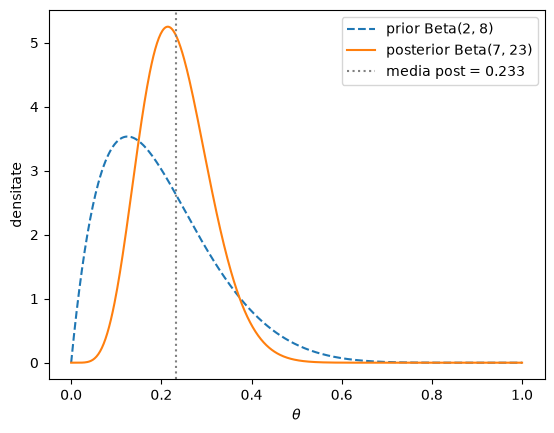

In [6]:
grid = np.linspace(0, 1, 500)

# prior
plt.plot(grid, beta.pdf(grid, alpha0, beta0), "--", label=f"prior Beta({alpha0}, {beta0})")

# posterior
plt.plot(grid, beta.pdf(grid, alpha_post, beta_post), label=f"posterior Beta({alpha_post}, {beta_post})")

# media posterior
plt.axvline(media_post, color="gray", ls=":", label=f"media post = {media_post:.3f}")

# axe
plt.xlabel(r"$\theta$")
plt.ylabel("densitate")

plt.legend()
plt.show()

## b)

Loturile sunt independente condiționat de $\theta$.

"După ambele loturi" implică că posteriorul de la a devine prior, cu $n_2 = 15$ și $y_2 = 3$.

$$\theta \mid y_1, y_2 \sim \text{Beta}(7 + 3,\ 23 + 15 - 3) = \text{Beta}(10, 35)$$

Calculăm $\text{Beta}(2, 8)$ cu $n = 35$ și $y = 8$.

In [3]:
n2, y2 = 15, 3   # al doilea lot

alpha_post2 = alpha_post + y2
beta_post2 = beta_post + n2 - y2

print(f"posterior: Beta({alpha_post2}, {beta_post2})")
print(f"media a posteriori (ambele loturi): {alpha_post2 / (alpha_post2 + beta_post2):.4f}")

posterior: Beta(10, 35)
media a posteriori (ambele loturi): 0.2222


## c)

Folosim doar al doilea lot ($n_2 = 15$, $y_2 = 3$), cu priorul inițial $\text{Beta}(2, 8)$:

$$\theta \mid y_2 \sim \text{Beta}(2 + 3,\ 8 + 15 - 3) = \text{Beta}(5, 20)$$

In [8]:
# doar al doilea lot, prior initial
alpha_c = alpha0 + y2
beta_c = beta0 + n2 - y2

post_b = beta(alpha_post2, beta_post2)
post_c = beta(alpha_c, beta_c)

print(f"b) media = {post_b.mean():.4f}, std = {post_b.std():.4f}")
print(f"c) media = {post_c.mean():.4f}, std = {post_c.std():.4f}")

b) media = 0.2222, std = 0.0613
c) media = 0.2000, std = 0.0784


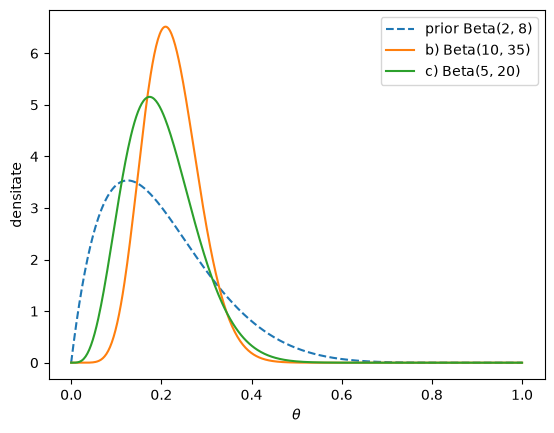

In [9]:
# prior
plt.plot(grid, beta.pdf(grid, alpha0, beta0), "--", label=f"prior Beta({alpha0}, {beta0})")

# b
plt.plot(grid, beta.pdf(grid, alpha_post2, beta_post2), label=f"b) Beta({alpha_post2}, {beta_post2})")

# c
plt.plot(grid, beta.pdf(grid, alpha_c, beta_c), label=f"c) Beta({alpha_c}, {beta_c})")

plt.xlabel(r"$\theta$")
plt.ylabel("densitate")

plt.legend()
plt.show()

In [10]:
print(f"b) media = {post_b.mean():.4f}, std = {post_b.std():.4f}")
print(f"c) media = {post_c.mean():.4f}, std = {post_c.std():.4f}")

b) media = 0.2222, std = 0.0613
c) media = 0.2000, std = 0.0784


### Comparație

Ponderea datelor într-un anumit caz este $\frac{n}{n + \alpha + \beta}$. Avem $\alpha = 2, \beta = 8$.

- b folosește $n = 35$ și $y = 8$ (rata $8/35 \approx 0.229$), deci datele au ponderea $35/45$ și media urcă la $0.222$.
- c folosește doar $n = 15$ și $y = 3$ (rata $3/15 = 0.2$), deci datele au ponderea $15/25$. Rata din date este egală cu media priorului, deci media nu se schimbă.

Primul lot ($5/20 = 0.25$) are o rată mai mare de defecte și lipsește în c, deci media din c este mai mică.

Posteriorul din c este mai lat (mai imprecis) deoarece are mai puține date.

b este cel mai corect pentru că folosește toată informația.